In [14]:
from anemone.inversion import *
from anemone.forwards import Forward
from anemone.system import Loop, Receiver, Waveform, FilterChain, ButterworthFilter
from anemone.experiment import compute_relstd

times = torch.logspace(-6,-3, 31)
fwrTD = Forward.example(times=times)

res_start = LogResistivity.smooth(torch.ones(31, dtype=torch.double)*40., torch.cumsum(torch.logspace(0.3,1,30), 0))
rho,thick = res_start.mod
rho[10:18] = 80.
rho[18:] = 30.
mod_true = LogResistivity.smooth(rho, torch.cumsum(thick,0))


dbdt_true = fwrTD(rho, thick).real#.exp()
d_relerr = compute_relstd(fwrTD.times, dbdt_true, current=1.)
# d_err = torch.log1p(d_relerr)
d_err = dbdt_true * d_relerr
d_obs = dbdt_true + dbdt_true * torch.randn_like(dbdt_true) * d_relerr

In [15]:
def fwraugment(log_resistivity):
    res = torch.from_numpy(log_resistivity).exp()
    dbdt = fwrTD(res, thick).numpy().T.real
    dM = np.diff(log_resistivity, axis=0)
    data = np.vstack([dbdt, dM])
    return data.T

In [16]:
import numpy as np
from numpy.linalg import inv
from time import perf_counter as timer

class EnsembleSmoother(fastJac):
    def __init__(self, data_observed, data_error, starting_model, forward_operator):
        super().__init__(data_observed, data_error, starting_model, forward_operator)
        
    def invert(self, n_sim=100, alpha=4, log=print):
        if isinstance(n_sim, float):
            n_sim = int(n_sim)

        lbnds = self.model.lbnds.numpy()
        ubnds = self.model.ubnds.numpy()
        print(lbnds[0], ubnds[0])

        n_data=len(self.data_observed)
        n_mpar=len(self.model.vec)

        Csim = np.zeros((n_sim, n_mpar))
        data_sim = np.zeros((n_sim, n_data))
        for i in range(n_sim):
            tmp_mod = torch.from_numpy(np.random.uniform(lbnds, ubnds))
            Csim[i] = self.model.make_physical(tmp_mod).numpy()
            # data_sim[i] = self.mforward(Csim[i])
        data_sim = np.nan_to_num(self.forward(Csim.T))
        self.Cstart = Csim.copy()

        # # # create vector of inflation coefficients such that
        # # Σ (1 / α_i) = 1
        # n = np.arange(n_iter).astype(float)+1
        
        if isinstance(alpha, list):
            alpha_all = alpha.copy()
        elif isinstance(alpha, float) or isinstance(alpha, int):
            n_iter = int(alpha)

            ralpha = np.ones(n_iter)
            ralpha[-1] = 5.
            ralpha /= ralpha.sum()
            alpha_all = 1./ralpha
        else:
            raise ValueError('alpha must be float, int or list')        



        noise = self.data_error
        Ce = np.diag(noise**2)
        Ce_sqrt = np.sqrt(Ce)

        tiled_data = np.nan_to_num(np.tile(self.data_observed, (n_sim, 1)))

        mod = Csim
        for k,alpha in enumerate(alpha_all):
            md = np.hstack((mod, data_sim))
            Cmod = np.cov(md.T)
            Cdd = Cmod[-n_data:, -n_data:]
            Cmd = Cmod[:n_mpar, -n_data:]
            dpert = tiled_data.copy()
            dpert += np.sqrt(alpha)*np.random.randn(n_sim*n_data).reshape(data_sim.shape)@Ce_sqrt
            mod_up = Cmd @ inv(Cdd + alpha*Ce) @ (dpert-data_sim).T
            mod += mod_up.T

            for i in range(n_sim):
                mod[i] = self.model.make_physical(torch.from_numpy(mod[i])).numpy()
            bt = timer()
            data_sim = np.nan_to_num(self.forward(mod.T))
            print(f'FW run time: {timer()-bt:.2f} sec')
            
            misfit = np.mean(((tiled_data-data_sim)/noise[None,:])**2, axis=-1)#**(0.5)
            good_models = (misfit<1.2).astype(int)
            log(f'iteration: {k+1}\t{good_models.sum()} models have a data misft < 1.2 \t alpha was : {alpha:.2f}')
            if good_models.sum() >= 0.95*n_sim:
                log(f'misfit is good after {k+1} iterations')
                break
        self.result = np.exp(mod)
        self.misfit= misfit
        return self

    def good_models(self, threshold=1.2):
        return self.result[self.misfit < threshold]

In [17]:
ralpha = 1./np.ones(4)
ralpha /= ralpha.sum()
alpha = 1./ralpha
print(ralpha, alpha)

[0.25 0.25 0.25 0.25] [4. 4. 4. 4.]


In [ ]:
d_aug = np.concatenate([d_obs.numpy(), np.zeros(res_start.n_layers-1)])
d_err_aug = np.concatenate([d_err.numpy(), np.ones(res_start.n_layers-1)*0.2])

es = EnsembleSmoother(d_aug, d_err_aug, res_start, fwraugment)
# es.invert(n_sim=500, alpha=[0.1, 0.5, 1., 2])
es.invert(n_sim=500, alpha=[1, 1, 1, 1, 1]);

-2.3025850929940455 9.903487552536127
FW run time: 13.87 sec
iteration: 1	0 models have a data misft < 1.2 	 alpha was : 1.00
FW run time: 13.36 sec
iteration: 2	22 models have a data misft < 1.2 	 alpha was : 1.00
FW run time: 13.51 sec
iteration: 3	465 models have a data misft < 1.2 	 alpha was : 1.00
FW run time: 13.39 sec
iteration: 4	499 models have a data misft < 1.2 	 alpha was : 1.00
misfit is good after 4 iterations


EnsembleSmoother(data_observed=array([ 4.18586660e-03,  5.15253540e-03,  6.09657061e-03,  6.59750661e-03,
        7.74958838e-03,  5.73278870e-03,  3.31365392e-03,  1.89762101e-03,
        1.03518576e-03,  5.65149171e-04,  3.48041379e-04,  1.85361217e-04,
        1.03242047e-04,  5.79954367e-05,  3.04477368e-05,  1.69778325e-05,
        9.03359755e-06,  4.75681726e-06,  2.66389824e-06,  1.40849379e-06,
        7.05667171e-07,  4.12293950e-07,  1.75682051e-07,  1.58726502e-07,
        4.20023251e-08,  5.09593863e-08,  1.34352345e-08,  1.13414757e-08,
        1.51223474e-08,  4.73319147e-09, -6.89998340e-09,  0.00000000e+00,
        0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000

$ \sum \alpha_i^{-1} = 1 $

pivot shape: (50, 31)
bin edges shape: (51,)


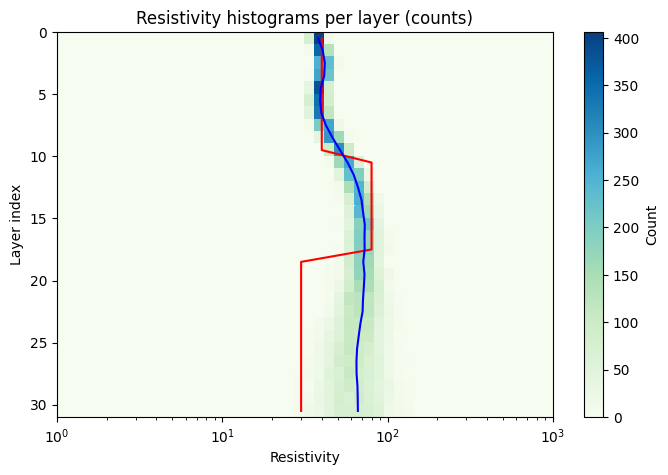

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# es.result: shape (n_sim, n_layers) = (300, 31)
res_vals = es.good_models(threshold=np.inf)

n_sim, n_layers = res_vals.shape

mres = np.mean(res_vals, axis=0)


res_bins = np.logspace(0, 3, 51)

n_bins = len(res_bins) - 1
pivot = np.zeros((n_bins, n_layers), dtype=int)

for j in range(n_layers):
    counts, _ = np.histogram(res_vals[:, j], bins=res_bins)
    pivot[:, j] = counts

print("pivot shape:", pivot.shape)  # (n_bins-1, 31)
print("bin edges shape:", res_bins.shape)

# Optional: visualize as a heatmap (y-axis = resistivity bins, x-axis = layer index)
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.pcolor(res_bins, np.arange(n_layers+1), pivot.T, cmap='GnBu')
ax.set_xscale('log')
ax.set_ylabel('Layer index')
ax.set_xlabel('Resistivity')
ax.set_title('Resistivity histograms per layer (counts)')
ax.plot(rho, np.arange(0, n_layers)+0.5, 'r-', label='True resistivity')
ax.plot(mres, np.arange(0, n_layers)+0.5, 'b-', label='Median estimated resistivity')
fig.colorbar(im, ax=ax, label='Count')
ax.invert_yaxis()
plt.show()

In [31]:
dbdt = fwrTD(res_vals.T, thick).real


In [32]:
dbdt.shape

torch.Size([500, 31])

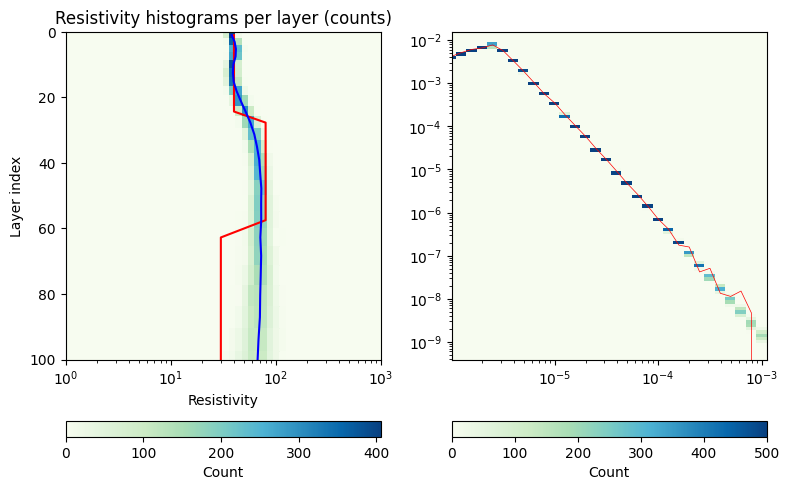

In [49]:
fig, axs = plt.subplots(1,2, figsize=(8, 5))
ax = axs[0]

n_sim, n_layers = res_vals.shape
mres = np.mean(res_vals, axis=0)
res_bins = np.logspace(0, 3, 51)

n_bins = len(res_bins) - 1
pivot = np.zeros((n_bins, n_layers), dtype=int)

for j in range(n_layers):
    counts, _ = np.histogram(res_vals[:, j], bins=res_bins)
    pivot[:, j] = counts

z = np.cumsum(np.append(np.insert(thick.numpy(), 0,0), thick.sum()+10))


im = ax.pcolor(res_bins, z, pivot.T, cmap='GnBu')
ax.set_xscale('log')
ax.set_ylabel('Layer index')
ax.set_xlabel('Resistivity')
ax.set_title('Resistivity histograms per layer (counts)')
ax.plot(rho, 0.5*(z[1:]+z[:-1]), 'r-', label='True resistivity')
ax.plot(mres, 0.5*(z[1:]+z[:-1]), 'b-', label='Median estimated resistivity')
fig.colorbar(im, ax=ax, orientation='horizontal', label='Count', fraction=0.05)
ax.set_ylim(100,0)

ax=axs[1]

n_sim,n_times = dbdt.shape
dbdt_bins = np.geomspace(dbdt.min()/2, dbdt.max()*2, 100)

n_bins = len(dbdt_bins) - 1
pivot = np.zeros((n_bins, n_times), dtype=int)

for j in range(n_times):
    counts, _ = np.histogram(dbdt[:, j], bins=dbdt_bins)
    pivot[:, j] = counts

t_axis = np.insert(fwrTD.times.numpy(), 0, fwrTD.times.min()*0.9)
t_axis *= np.sqrt(t_axis[2]/t_axis[1])

im = ax.pcolor(t_axis, dbdt_bins, pivot, cmap='GnBu')
ax.plot(fwrTD.times, d_obs, 'r-', linewidth=0.5)

ax.set_xscale('log')
ax.set_yscale('log')
fig.colorbar(im, ax=ax, orientation='horizontal', label='Count', fraction=0.05)
plt.tight_layout()

In [193]:
def fwrNOTaugment(log_resistivity):
    res = torch.from_numpy(log_resistivity).exp()
    dbdt = fwrTD(res, res_start.thickness).numpy()
    return dbdt

In [177]:
es0 = EnsembleSmoother(d_obs.numpy(), d_err.numpy(), res_start, fwrNOTaugment)
es0.invert(n_sim=100, alpha=[3,3,0.5,0.5,0.5])

-2.3025850929940455 9.903487552536127
FW run time: 7.74 sec
iteration: 1	0 models have a data misft < 1.2 	 alpha was : 3.00
FW run time: 7.18 sec
iteration: 2	0 models have a data misft < 1.2 	 alpha was : 3.00
FW run time: 6.76 sec
iteration: 3	0 models have a data misft < 1.2 	 alpha was : 0.50
FW run time: 7.17 sec
iteration: 4	0 models have a data misft < 1.2 	 alpha was : 0.50
FW run time: 7.44 sec
iteration: 5	0 models have a data misft < 1.2 	 alpha was : 0.50


pivot shape: (50, 31)
bin edges shape: (51,)


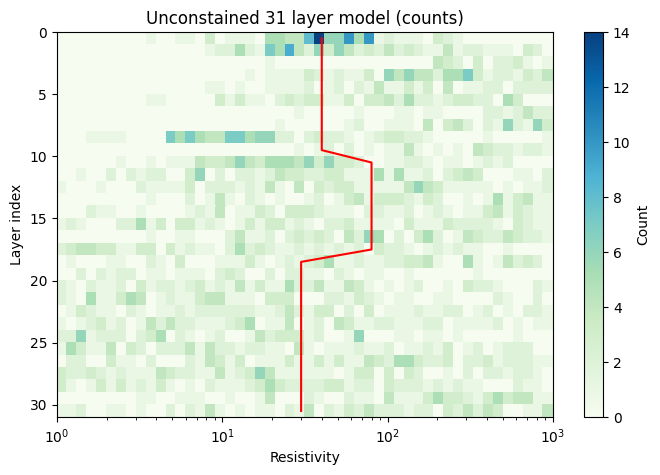

In [179]:
import numpy as np
import matplotlib.pyplot as plt

# es.result: shape (n_sim, n_layers) = (300, 31)
res_vals = es0.good_models(threshold=np.inf)
n_sim, n_layers = res_vals.shape


res_bins = np.logspace(0, 3, 51)

n_bins = len(res_bins) - 1
pivot = np.zeros((n_bins, n_layers), dtype=int)

for j in range(n_layers):
    counts, _ = np.histogram(res_vals[:, j], bins=res_bins)
    pivot[:, j] = counts

print("pivot shape:", pivot.shape)  # (n_bins-1, 31)
print("bin edges shape:", res_bins.shape)

# Optional: visualize as a heatmap (y-axis = resistivity bins, x-axis = layer index)
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.pcolor(res_bins, np.arange(n_layers+1), pivot.T, cmap='GnBu')
ax.set_xscale('log')
ax.set_ylabel('Layer index')
ax.set_xlabel('Resistivity')
ax.set_title('Unconstained 31 layer model (counts)')
ax.plot(rho, np.arange(0, n_layers)+0.5, 'r-', label='True resistivity')
fig.colorbar(im, ax=ax, label='Count')
ax.invert_yaxis()
plt.show()